# Task 5 – Inference on a raw image

I used the trained 512 × 512 root segmentation model on `task5_test_image.png`. The image is much bigger than the model input, so I first find the Petri dish, predict overlapping patches, and put them back together.

At the end I place the prediction back at the original image coordinates and save a black-and-white mask with the same dimensions as the input image.

In [1]:
# import things

import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# IMPORTANT: same Keras package used during training
import tf_keras as keras
from tf_keras import backend as K
from tf_keras import layers

print("TensorFlow version:", tf.__version__)

I0000 00:00:1790077208.408461 3933453 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790077208.455438 3933453 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790077212.403492 3933453 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


In [2]:
def f1(y_true, y_pred):
    """Calculate the same F1 metric used during model training."""
    def recall_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Positives = K.sum(K.round(K.clip(y_true, 0, 1)))
        recall = TP / (Positives + K.epsilon())
        return recall
    
    def precision_m(y_true, y_pred):
        TP = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        Pred_Positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        precision = TP / (Pred_Positives + K.epsilon())
        return precision
    
    precision = precision_m(y_true, y_pred)
    recall = recall_m(y_true, y_pred)
    
    return 2 * (
        (precision * recall)
        /
        (precision + recall + K.epsilon())
    )


@keras.utils.register_keras_serializable(package="RootSeg")
class GroupNormalization(layers.Layer):

    """Recreate the custom normalization layer when loading the model."""
    def __init__(
        self,
        groups=8,
        epsilon=1e-5,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.groups = groups
        self.epsilon = epsilon


    def build(self, input_shape):

        channels = int(input_shape[-1])

        if channels % self.groups != 0:
            raise ValueError(
                f"Channels ({channels}) must be divisible "
                f"by groups ({self.groups})."
            )

        self.gamma = self.add_weight(
            name="gamma",
            shape=(channels,),
            initializer="ones",
            trainable=True
        )

        self.beta = self.add_weight(
            name="beta",
            shape=(channels,),
            initializer="zeros",
            trainable=True
        )

        super().build(input_shape)


    def call(self, inputs):

        shape = tf.shape(inputs)

        batch = shape[0]
        height = shape[1]
        width = shape[2]
        channels = shape[3]

        x = tf.reshape(
            inputs,
            [
                batch,
                height,
                width,
                self.groups,
                channels // self.groups
            ]
        )

        mean, variance = tf.nn.moments(
            x,
            axes=[1, 2, 4],
            keepdims=True
        )

        x = (
            x - mean
        ) / tf.sqrt(
            variance + self.epsilon
        )

        x = tf.reshape(
            x,
            shape
        )

        return (
            x * self.gamma
            + self.beta
        )


    def get_config(self):

        config = super().get_config()

        config.update({
            "groups": self.groups,
            "epsilon": self.epsilon
        })

        return config


    

In [3]:
# Load the model you trained in task5_training.ipynb

patch_size = 512

model_file_name = (
    f'NikaSoleimanzadeh_244258_unet_model_{512}px.h5'
)

model = keras.models.load_model(
    model_file_name,
    custom_objects={
        "f1": f1,
        "GroupNormalization": GroupNormalization,
        "RootSeg>GroupNormalization": GroupNormalization
    },
    compile=False
)

print("Loaded model:", model_file_name)
print("Model input shape:", model.input_shape)
print("Model output shape:", model.output_shape)

assert model.input_shape[1:] == (512, 512, 1)

print("✅ Correct 512 × 512 model loaded.")

W0000 00:00:1790077252.370116 3933453 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1790077252.371401 3933453 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 43487 MB memory:  -> device: 0, name: NVIDIA L40S, pci bus id: 0000:81:00.0, compute capability: 8.9


Loaded model: NikaSoleimanzadeh_244258_unet_model_512px.h5
Model input shape: (None, 512, 512, 1)
Model output shape: (None, 512, 512, 1)
✅ Correct 512 × 512 model loaded.


In [4]:
# Define any functions you need to process the mask e.g. Task 2


def find_petri_dish(image):

    """Find the Petri dish bounding box using traditional CV."""
    blurred = cv2.GaussianBlur(
        image,
        (5, 5),
        0
    )

    _, binary = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if len(contours) == 0:
        raise RuntimeError(
            "Could not detect the Petri dish."
        )

    dish_contour = max(
        contours,
        key=cv2.contourArea
    )

    x, y, w, h = cv2.boundingRect(
        dish_contour
    )

    # Remove only the left/right physical Petri wall.
    SIDE_INSET = 20

    x = x + SIDE_INSET
    w = w - (2 * SIDE_INSET)

    return x, y, w, h



def pad_for_patches(
    image,
    patch_size=512,
    stride=256
):

    """Pad the dish image so sliding windows cover its edges."""
    h, w = image.shape

    if h <= patch_size:
        pad_h = patch_size - h

    else:
        remainder_h = (
            h - patch_size
        ) % stride

        pad_h = (
            0
            if remainder_h == 0
            else stride - remainder_h
        )


    if w <= patch_size:
        pad_w = patch_size - w

    else:
        remainder_w = (
            w - patch_size
        ) % stride

        pad_w = (
            0
            if remainder_w == 0
            else stride - remainder_w
        )


    padded = cv2.copyMakeBorder(
        image,
        0,
        pad_h,
        0,
        pad_w,
        cv2.BORDER_REFLECT
    )

    return padded



def tiled_prediction(
    model,
    image,
    patch_size=512,
    stride=256,
    batch_size=4
):

    # Same normalization as training
    """Predict overlapping patches and combine them into one map."""
    image_normalized = (
        image.astype(np.float32)
        / 255.0
    )

    h, w = image_normalized.shape


    prediction_sum = np.zeros(
        (h, w),
        dtype=np.float32
    )

    prediction_count = np.zeros(
        (h, w),
        dtype=np.float32
    )


    patches = []
    coordinates = []


    def predict_batch(
        patch_batch,
        coordinate_batch
    ):

        if len(patch_batch) == 0:
            return

        batch = np.stack(
            patch_batch,
            axis=0
        )

        predictions = model.predict(
            batch,
            verbose=0
        )

        predictions = predictions[..., 0]


        for prediction, (y, x) in zip(
            predictions,
            coordinate_batch
        ):

            prediction_sum[
                y:y + patch_size,
                x:x + patch_size
            ] += prediction

            prediction_count[
                y:y + patch_size,
                x:x + patch_size
            ] += 1


    patch_counter = 0


    for y in range(
        0,
        h - patch_size + 1,
        stride
    ):

        for x in range(
            0,
            w - patch_size + 1,
            stride
        ):

            patch = image_normalized[
                y:y + patch_size,
                x:x + patch_size
            ]

            patch = patch[..., np.newaxis]

            patches.append(patch)
            coordinates.append((y, x))

            patch_counter += 1


            if len(patches) == batch_size:

                predict_batch(
                    patches,
                    coordinates
                )

                patches = []
                coordinates = []


    # Final incomplete batch
    predict_batch(
        patches,
        coordinates
    )


    probability_map = (
        prediction_sum
        /
        np.maximum(
            prediction_count,
            1
        )
    )


    print(
        "Number of patches predicted:",
        patch_counter
    )

    return probability_map

Input image shape:
3006 4112


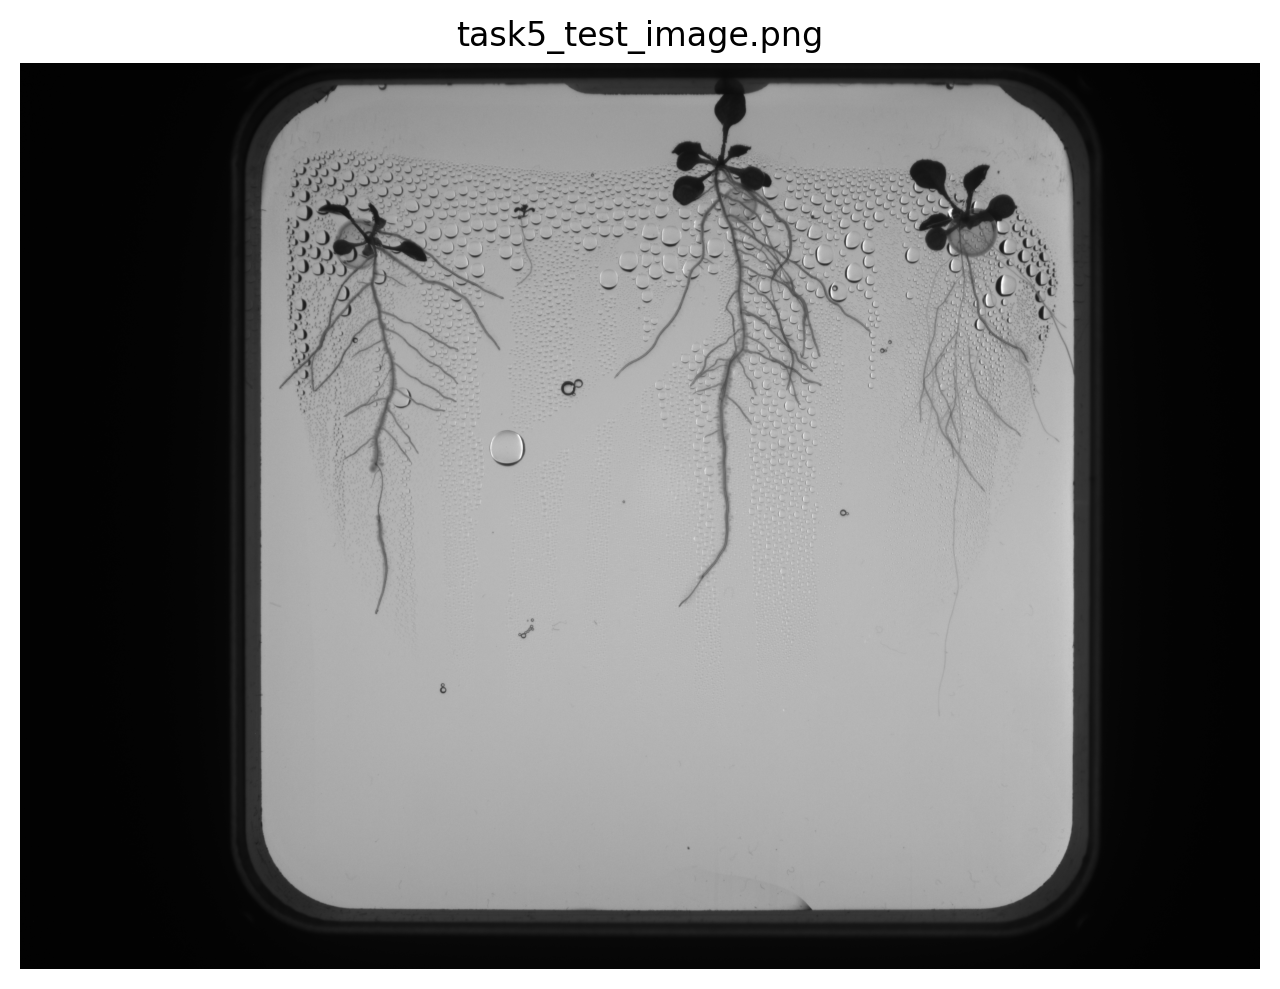

In [5]:
# Load the test image

task5_test_image_path = 'task5_test_image.png'

image = cv2.imread(
    task5_test_image_path,
    0
)

if image is None:
    raise FileNotFoundError(
        task5_test_image_path
    )

h, w = image.shape

print("Input image shape:")
print(h, w)


plt.figure(
    dpi=200,
    figsize=(8, 6)
)

plt.imshow(
    image,
    cmap='gray'
)

plt.title(
    'task5_test_image.png'
)

plt.axis('off')

plt.show()

Petri dish bounding box: 817 71 2660 2742
Petri dish shape: (2742, 2660)


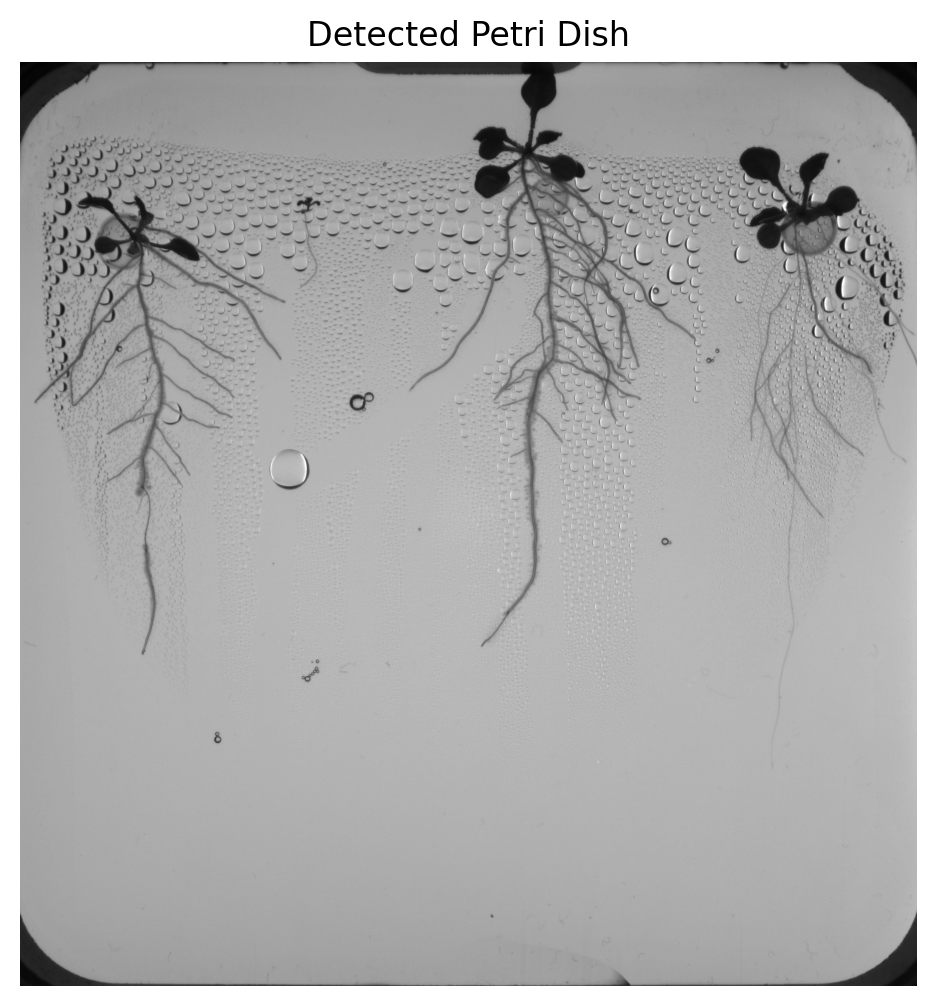

In [6]:
# Find the petri dish

x, y, dish_w, dish_h = find_petri_dish(
    image
)

petri_dish = image[
    y:y + dish_h,
    x:x + dish_w
]

print(
    "Petri dish bounding box:",
    x,
    y,
    dish_w,
    dish_h
)

print(
    "Petri dish shape:",
    petri_dish.shape
)


plt.figure(
    dpi=200,
    figsize=(8, 6)
)

plt.imshow(
    petri_dish,
    cmap='gray'
)

plt.title(
    'Detected Petri Dish'
)

plt.axis('off')

plt.show()

In [7]:
# Pad the petri dish

STRIDE = 256

petri_dish_padded = pad_for_patches(
    petri_dish,
    patch_size=patch_size,
    stride=STRIDE
)

print(
    "Original Petri dish shape:",
    petri_dish.shape
)

print(
    "Padded Petri dish shape:",
    petri_dish_padded.shape
)

Original Petri dish shape: (2742, 2660)
Padded Petri dish shape: (2816, 2816)


I0000 00:00:1790077277.427702 3941746 cuda_dnn.cc:461] Loaded cuDNN version 90701


Number of patches predicted: 100
Prediction values: [0 1]
Prediction shape: (2742, 2660)


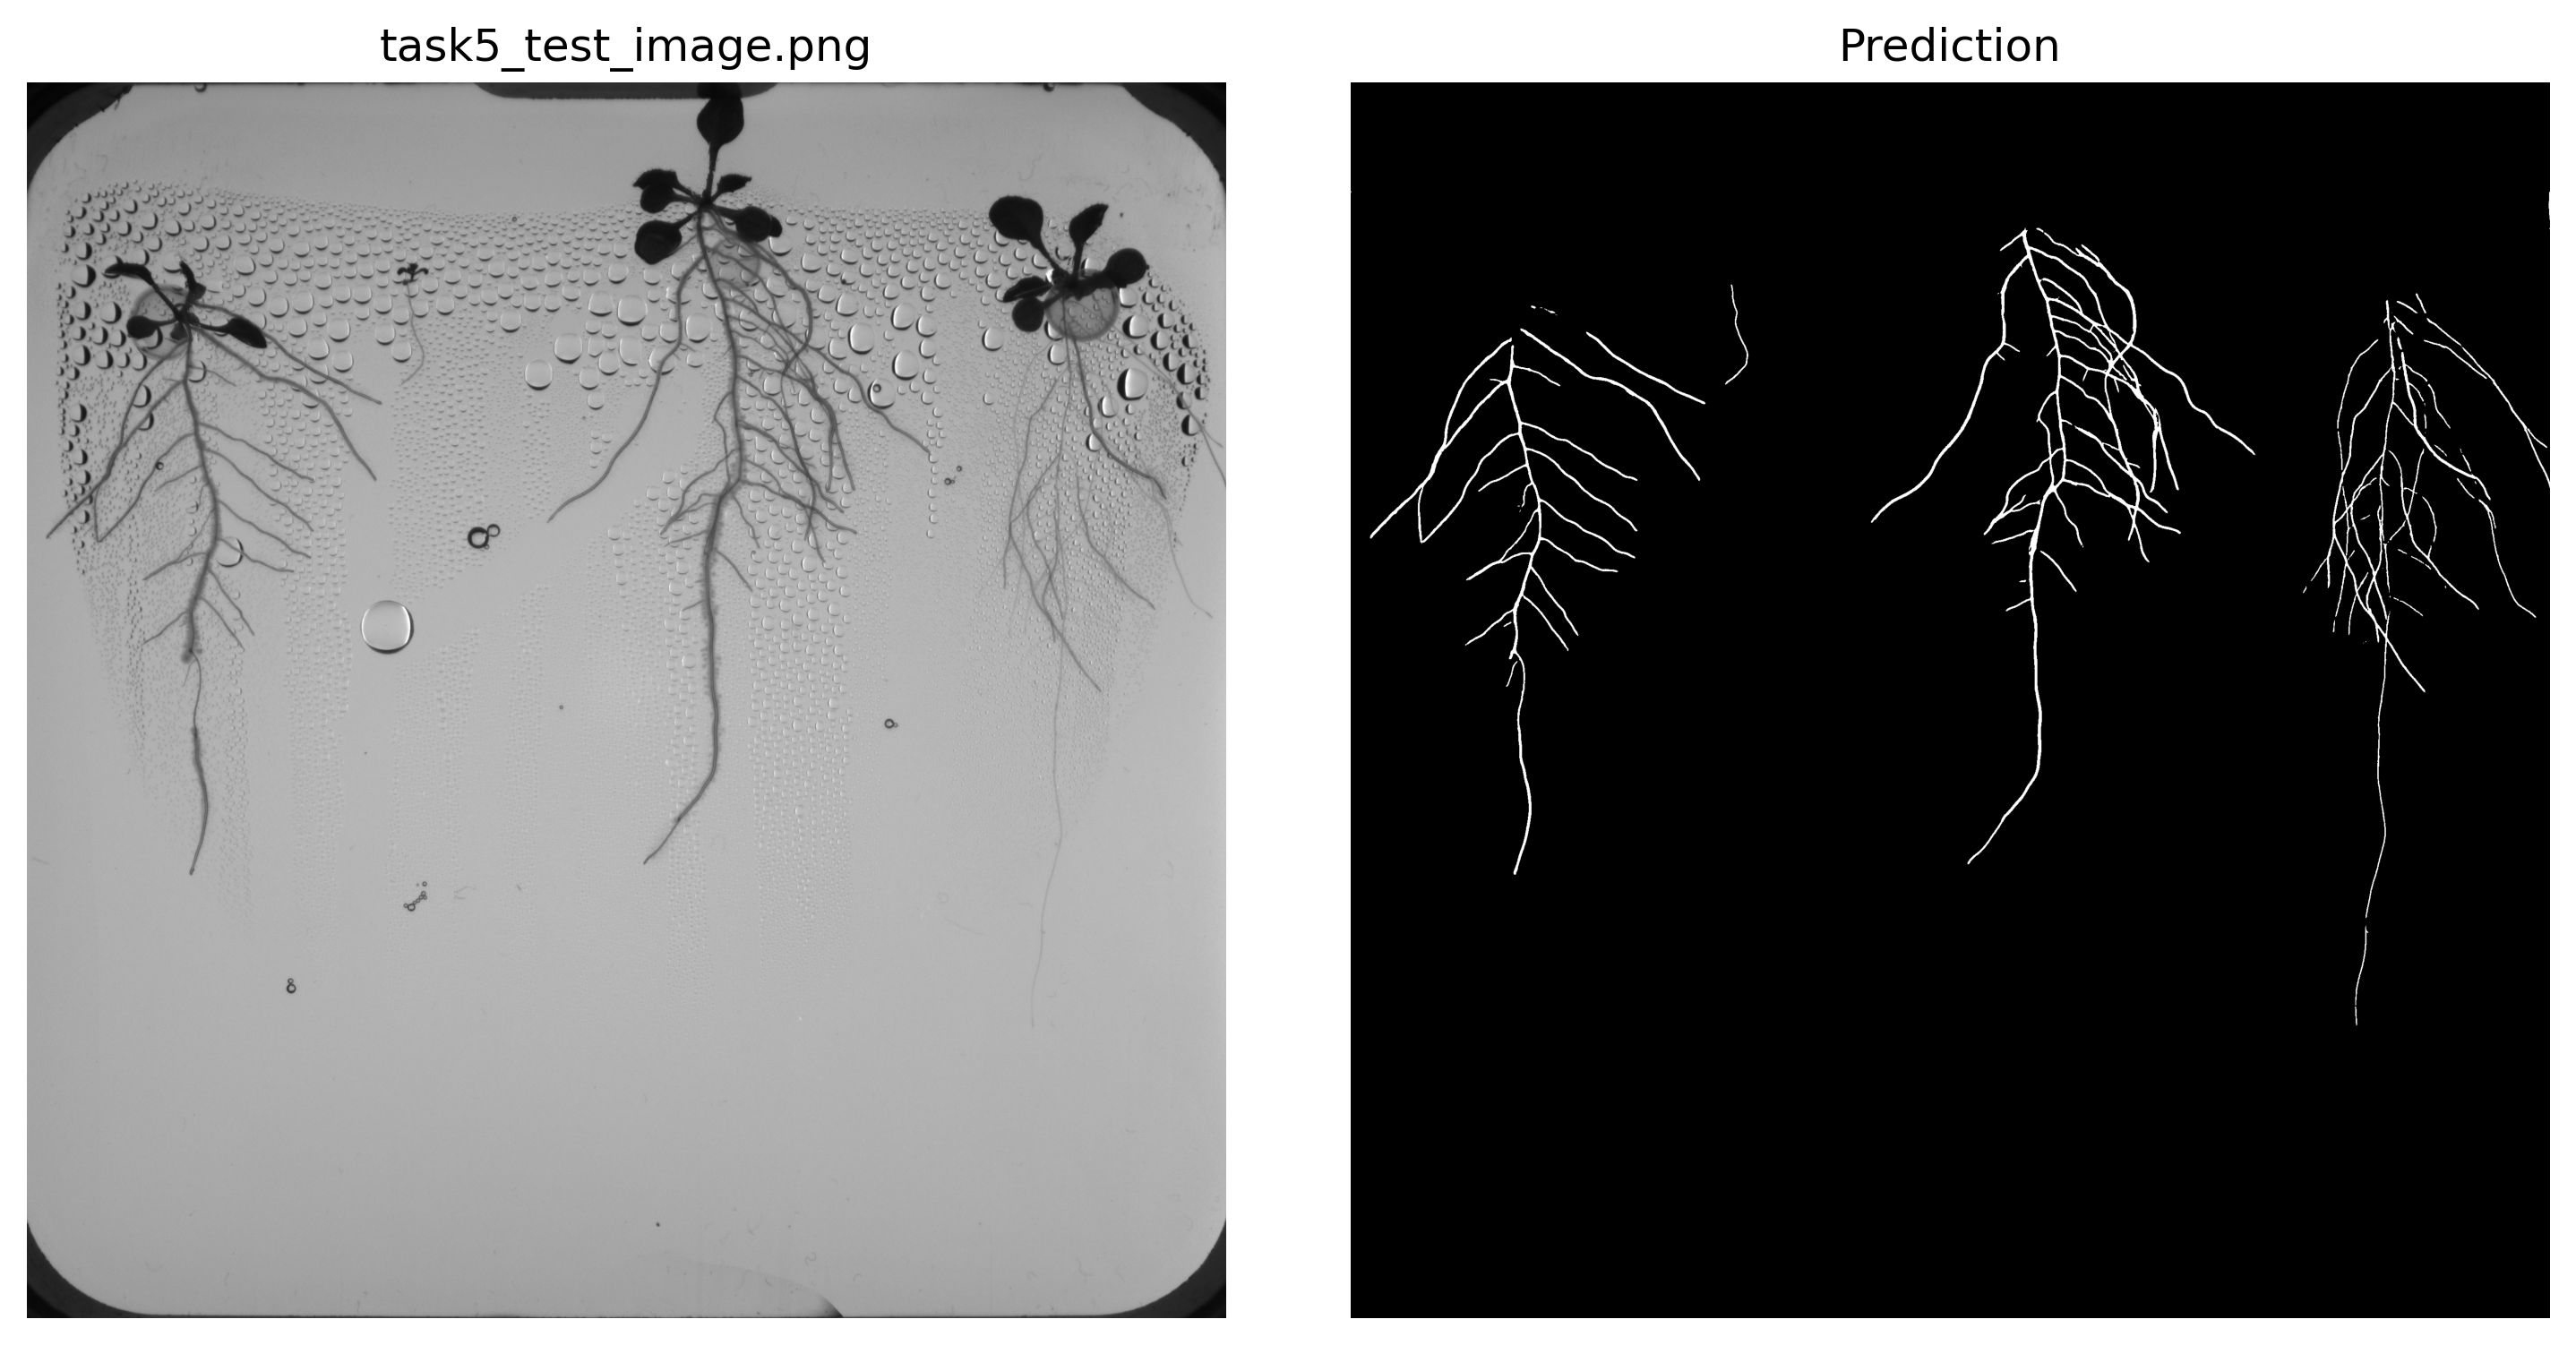

In [8]:
# PATCH

# PREDICT

# UNPATCH


probability_map_padded = tiled_prediction(
    model=model,
    image=petri_dish_padded,
    patch_size=patch_size,
    stride=STRIDE,
    batch_size=4
)


# Remove the padding again.
petri_h, petri_w = petri_dish.shape

probability_map = probability_map_padded[
    :petri_h,
    :petri_w
]


# BUas F1 uses rounding, equivalent to threshold 0.5.
THRESHOLD = 0.50

predicted_mask = (
    probability_map >= THRESHOLD
).astype(np.uint8)


print(
    "Prediction values:",
    np.unique(predicted_mask)
)

print(
    "Prediction shape:",
    predicted_mask.shape
)


f, ax = plt.subplots(
    1,
    2,
    dpi=300,
    figsize=(10, 5)
)

ax[0].imshow(
    petri_dish,
    cmap='gray'
)

ax[0].axis('off')

ax[0].set_title(
    'task5_test_image.png'
)


ax[1].imshow(
    predicted_mask,
    cmap='gray'
)

ax[1].axis('off')

ax[1].set_title(
    'Prediction'
)

plt.tight_layout()
plt.show()

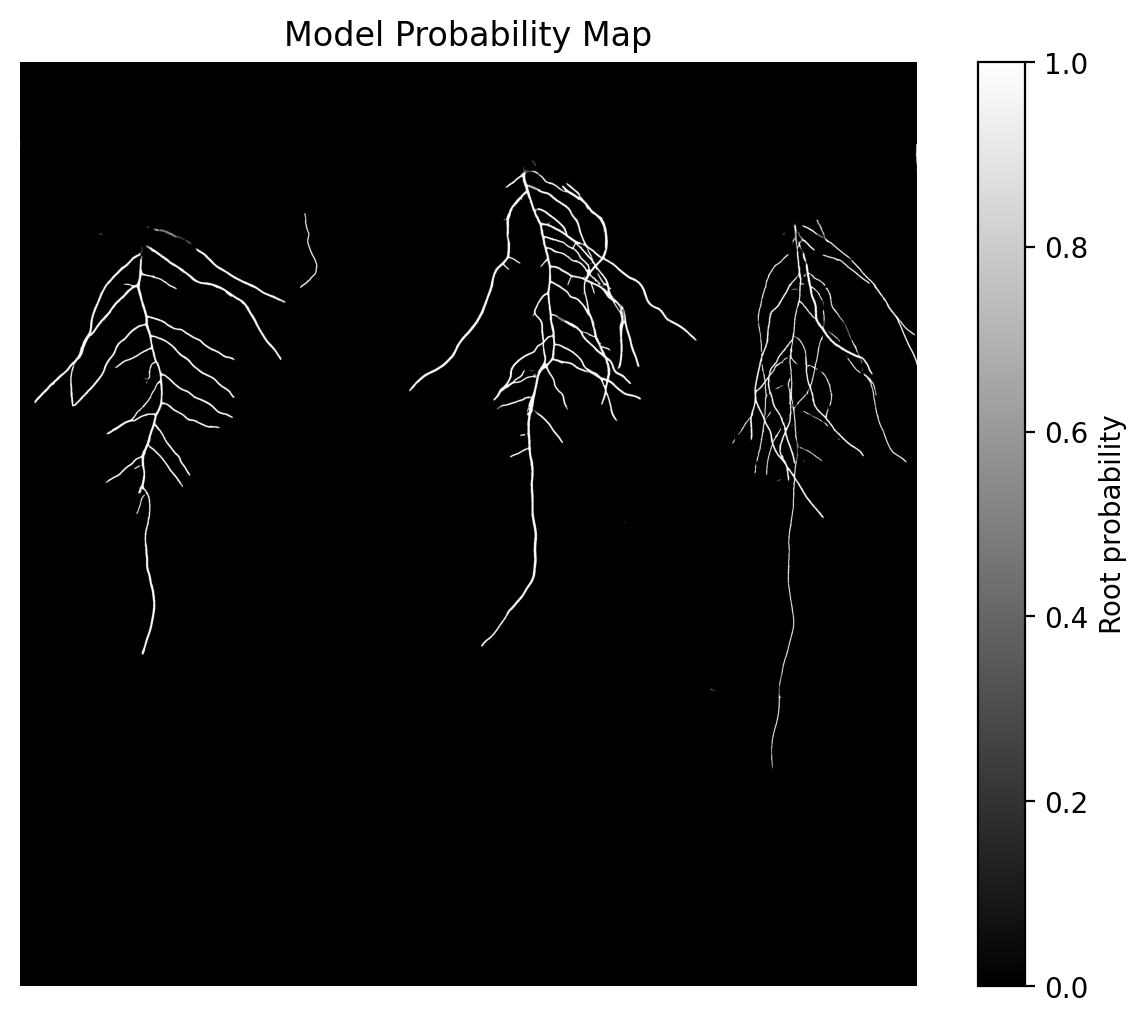

In [9]:
plt.figure(
    dpi=200,
    figsize=(8, 6)
)

plt.imshow(
    probability_map,
    cmap='gray',
    vmin=0,
    vmax=1
)

plt.colorbar(
    label='Root probability'
)

plt.title(
    'Model Probability Map'
)

plt.axis('off')

plt.show()

In [10]:
predicted_mask.shape, image.shape

((2742, 2660), (3006, 4112))

## Putting the mask back into the original image

The patch prediction only covers the cropped dish, so it is smaller than the raw image. I place the mask back at the original dish coordinates and leave the surrounding pixels black. I also check that the final mask has the same shape as the input.

In [11]:
# Apply the corrections

predicted_mask_corrected = np.zeros(
    image.shape,
    dtype=np.uint8
)


predicted_mask_corrected[
    y:y + dish_h,
    x:x + dish_w
] = predicted_mask


print(
    "Corrected prediction shape:",
    predicted_mask_corrected.shape
)

print(
    "Original image shape:",
    image.shape
)

print(
    "Mask values:",
    np.unique(
        predicted_mask_corrected
    )
)


assert (
    predicted_mask_corrected.shape
    ==
    image.shape
)

assert set(
    np.unique(
        predicted_mask_corrected
    )
).issubset({0, 1})


predicted_mask_corrected.shape

Corrected prediction shape: (3006, 4112)
Original image shape: (3006, 4112)
Mask values: [0 1]


(3006, 4112)

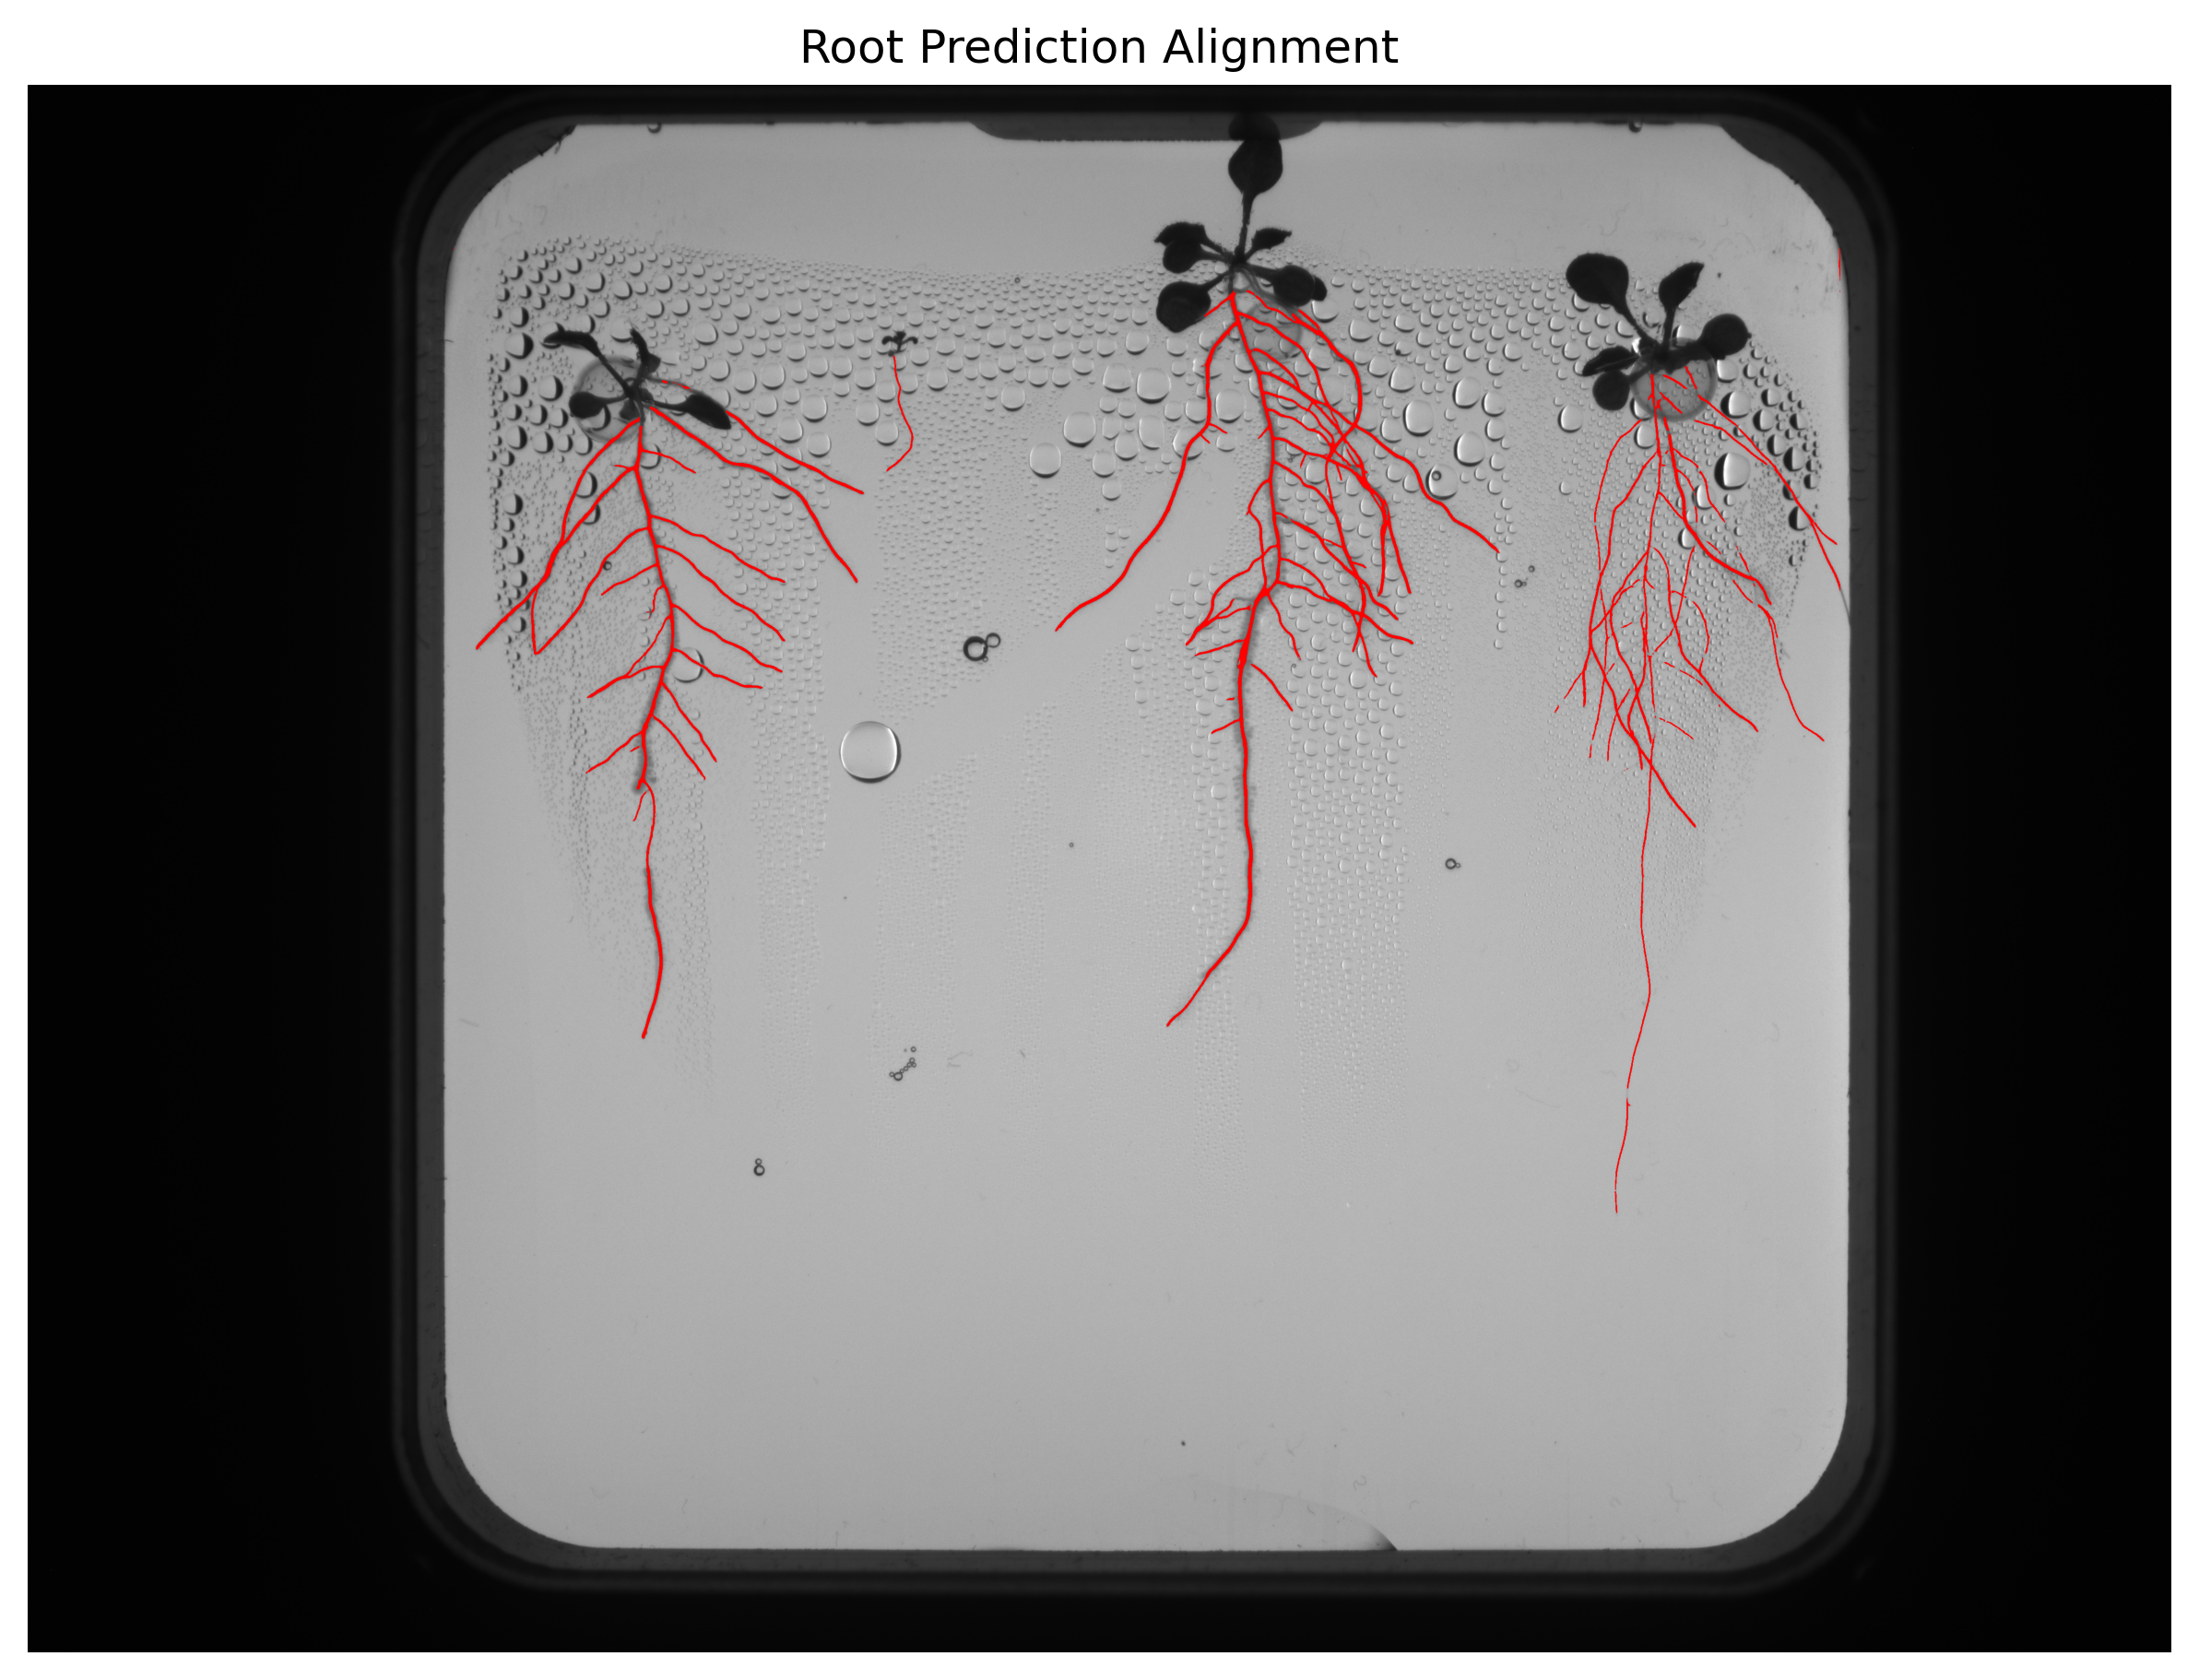

In [12]:
# REQUIREMENT: Predicted roots must align with the original image.
# REQUIREMENT: Plot such an image to prove alignment.

image_rgb = cv2.cvtColor(
    cv2.imread(
        task5_test_image_path
    ),
    cv2.COLOR_BGR2RGB
)


overlay_image = image_rgb.copy()


# Paint predicted root pixels red.
overlay_image[
    predicted_mask_corrected == 1
] = [255, 0, 0]


plt.figure(
    dpi=300,
    figsize=(10, 8)
)

plt.imshow(
    overlay_image
)

plt.title(
    'Root Prediction Alignment'
)

plt.axis('off')

plt.show()

In [14]:
# REQUIREMENT: Save the predicted mask, it is a deliverable.
# REQUIREMENT: Input/Output size must be the same.
# REQUIREMENT: Predicted roots must align with the original image.
# REQUIREMENT: The predicted mask must be binary.
# REQUIREMENT: Non-root pixels must be 0, root pixels must be 255 (unlike Task 1)
# REQUIREMENT: naming convention task5_test_image_prediction_studentname_studentnumber.png


mask_image = (
    predicted_mask_corrected * 255
).astype(np.uint8)


# ------------------------------------------------------------
# FINAL REQUIREMENT CHECKS
# ------------------------------------------------------------

assert (
    predicted_mask_corrected.shape
    ==
    image.shape
), "Input and output dimensions do not match."


assert set(
    np.unique(mask_image)
).issubset(
    {0, 255}
), "Mask is not binary 0/255."


print(
    "Input shape:",
    image.shape
)

print(
    "Output shape:",
    mask_image.shape
)

print(
    "Final pixel values:",
    np.unique(mask_image)
)


# ------------------------------------------------------------
# SAVE DELIVERABLE
# ------------------------------------------------------------

output_file = (
    'task5_test_image_prediction_'
    'nikasoleimanzadeh_244258.png'
)


success = cv2.imwrite(
    output_file,
    mask_image
)


if not success:
    raise RuntimeError(
        "Prediction could not be saved."
    )


print()
print(
    "✅ DELIVERABLE SAVED:"
)

print(
    output_file
)

Input shape: (3006, 4112)
Output shape: (3006, 4112)
Final pixel values: [  0 255]

✅ DELIVERABLE SAVED:
task5_test_image_prediction_nikasoleimanzadeh_244258.png


## Final output

The model was trained on the prepared patches from Y2B_23 and Y2B_24, with the `val_` images from Y2B_25 reserved for validation. My recorded best validation F1 is **0.8024**.

The last code cell saves the actual binary prediction as a PNG. I need to submit that saved PNG file, not a screenshot of the plot, because the saved version keeps the original dimensions and the 0/255 pixel values.